# M3 experiments: analyses of the corruption study (no training, no new corruption runs)
Run order: inventory → m3_build_verify → train_m3 → corruption → **analysis**

Run on: Colab **L4 GPU** (only section 8 uses the GPU: about 2 min of inference). About 25-35 min, about 2-3 compute
units (estimate).

0. Setup, code (SHA-256 checked), Nepal data (tier3)
1. Check: repeated post-image hashes vs `valid_px == 0`
2. Check: timing reconciliation (what each GPU figure measures)
3. **Between-family paired tests**, M2 vs M1 CE and M3 vs M1 CE (absolute and degradation; image-only and
   image+seed intervals; seed-pair spread)
4-5. **Unexpected gains and destroyed-F1 increases** (class shifts, confusion sources, score decomposition,
   per-seed consistency)
6-7. **Corruption artefact checks**: numeric checks of the corruptions and a zoomed visual check
8. **Prediction maps**: clean and severity-3 maps for the six sample crops (seed 0 of each main family; the EXPLORATORY
   ablation in separate figures)
9. Preservation check and summary

Inputs: the corruption notebook's files in `m3_experiments/corruption/` (read only). Outputs: `results/phase6/` and
`figures/phase6/` (folder names as on Drive). Evaluation status as before: M0, M1 CE, M1 Dice+focal, M2 = frozen 18 Nov
set; M3 = post-hoc, not blind; ablation = EXPLORATORY, one seed.

## 0. Setup

In [ ]:
# GPU check, Drive mount and project paths
!nvidia-smi --query-gpu=name,memory.total --format=csv
import os, sys, json, time, hashlib, datetime, shutil, subprocess, gc, random
from google.colab import drive
drive.mount("/content/drive")
D = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT"
CK, EXTRAS = f"{D}/checkpoints", f"{D}/eval_extras"
EXP = f"{D}/m3_experiments"
X, MAN = "/content/xbd", "/content/xbd/rscc_flood_manifest.csv"
CODE = "/content/m3code"
# out(): every path this notebook writes to is built here; anything outside m3_experiments/ raises
_EXP_REAL = os.path.realpath(EXP)
def out(*parts):
    p = os.path.realpath(os.path.join(EXP, *parts))
    if not (p == _EXP_REAL or p.startswith(_EXP_REAL + os.sep)):
        raise ValueError(f"refusing to write outside m3_experiments: {p}")
    return p
# Write JSON, converting numpy values to plain Python numbers
def jdump(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
# Size and modification time of every existing project file (read only)
def snapshot():
    snap = {}
    for name in sorted(os.listdir(D)):
        if name != "m3_experiments":
            snap[f"[top] {name}"] = os.path.getmtime(f"{D}/{name}")
    for root in (CK, EXTRAS, f"{D}/figures"):
        for dp, _, fs in os.walk(root):
            for fn in fs:
                st = os.stat(os.path.join(dp, fn)); snap[os.path.relpath(os.path.join(dp, fn), D)] = [st.st_size, st.st_mtime]
    return snap
# Snapshot before any work, session start time and GPU name
BEFORE = snapshot()
SESSION = {"session_start": datetime.datetime.now().isoformat(timespec="seconds"),
           "gpu": subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()}
# Output folders for this notebook
for s in ["results/phase6", "figures/phase6/qualitative", "figures/phase6/qualitative_EXPLORATORY_ablation"]:
    os.makedirs(out(s), exist_ok=True)
# Fresh clone of the repository, pinned to commit 8f10e61 and installed in editable mode
%cd /content
!rm -rf /content/FloodVerify
!git clone -q https://github.com/aaarrvind/FloodVerify.git /content/FloodVerify
!git -C /content/FloodVerify checkout -q 8f10e61
!pip install -q -e /content/FloodVerify --no-deps jsonschema
sys.path.insert(0, "/content/FloodVerify/src")
# Copy the earlier code back from Drive and check it against MANIFEST.json
os.makedirs(CODE, exist_ok=True); sys.path.insert(0, CODE)
def sha(p): return hashlib.sha256(open(p, "rb").read()).hexdigest()
MANI = json.load(open(out("code", "MANIFEST.json")))
for fn in ("m3_model.py", "m3_register.py", "metrics_ext.py", "corruption.py", "corruption_eval.py", "corruption_analysis.py"):
    shutil.copy(out("code", fn), f"{CODE}/{fn}")
    assert sha(f"{CODE}/{fn}") == MANI["files"][fn], f"{fn} differs from its recorded version"
print("Stage 3-5 code verified")

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Mounted at /content/drive
/content
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for floodsitrep (pyproject.toml) ... done
Stage 3-5 code verified


### `phase6_analysis.py`: analysis functions
Numpy and scipy only; uses the saved corruption-study files and re-runs nothing.
- `between_family(...)`: compares two families on the same Nepal images, as the difference in absolute scores and in
  degradation from each family's own clean pass. Two 95% intervals: resampling images only (the trained checkpoints held
  fixed), and resampling images and each family's 3 seeds (coarse: only 10 distinct seed combinations per family). Also
  the 9 seed-pair differences, and how many share the sign of the mean.
- `class_shift(...)`: where ground-truth building pixels end up, destroyed true and false positives and their sources,
  per-class precision, recall and F1, and the score split into 0.3 x localisation + 0.7 x damage harmonic mean.
- `artifact_diagnostics(...)`: numeric checks of a corrupted post crop against the clean one (PSNR, brightness change,
  newly saturated pixels, change near no-data edges, JPEG blockiness).

In [ ]:
%%writefile /content/m3code/phase6_analysis.py
"""Phase 6 analyses (numpy/scipy; no torch). Uses the corruption-study files already on Drive; nothing is re-run.

between_family(...)       paired comparison of two families on the SAME Nepal images:
                            absolute:    mean_seeds m(A, cond) - mean_seeds m(B, cond)
                            degradation: mean_seeds [m(A,cond) - m(A,clean)] - mean_seeds [m(B,cond) - m(B,clean)]
                            relative degradation difference likewise with (m(cond)-m(clean))/m(clean)
                          Interval 1 ("images"): images resampled with replacement (shared by every checkpoint); the 6
                          trained checkpoints are held fixed, so it answers "for THESE trained models, how much could the
                          difference change with other images of this kind". Interval 2 ("images + seeds"): additionally
                          resamples the 3 seeds of each family with replacement; with 3 seeds this is coarse (10 distinct
                          seed multisets per family) and only indicative of training-seed variability.
                          Also the 9 seed-pair differences (each A seed minus each B seed): min, max, and how many share
                          the sign of the family-mean difference.
class_shift(...)          where ground-truth building pixels go (predicted class shares), destroyed TP/FP/FN and their
                          sources, per-class precision/recall/F1, and the score decomposition 0.3*loc + 0.7*HM.
artifact_diagnostics(...) numeric checks of a corrupted post crop against the clean one.
"""
import numpy as np

from corruption_analysis import metrics_on

NAMES = ["background", "no_damage", "minor", "major", "destroyed"]


def _family_metrics(ils, idx, keys):
    return [{k: v for k, v in metrics_on(il, idx).items() if k in keys} for il in ils]


def between_family(A_clean, A_cond, B_clean, B_cond, keys, n_boot=1000, seed=0, with_degradation=True):
    """A_*/B_*: lists of image-level dicts (one per seed), all covering the same images in the same order."""
    ids = A_clean[0]["img_ids"]
    for il in A_clean + A_cond + B_clean + B_cond:
        assert il["img_ids"] == ids
    n = len(ids)

    def stats(idx, sa=None, sb=None):
        sa = range(len(A_cond)) if sa is None else sa
        sb = range(len(B_cond)) if sb is None else sb
        ac, ax = _family_metrics([A_clean[i] for i in sa], idx, keys), _family_metrics([A_cond[i] for i in sa], idx, keys)
        bc, bx = _family_metrics([B_clean[i] for i in sb], idx, keys), _family_metrics([B_cond[i] for i in sb], idx, keys)
        out = {}
        for k in keys:
            mA, mB = np.mean([m[k] for m in ax]), np.mean([m[k] for m in bx])
            out[(k, "abs")] = mA - mB
            if with_degradation:
                dA = np.mean([x[k] - c[k] for x, c in zip(ax, ac)])
                dB = np.mean([x[k] - c[k] for x, c in zip(bx, bc)])
                rA = np.mean([(x[k] - c[k]) / c[k] if c[k] else np.nan for x, c in zip(ax, ac)])
                rB = np.mean([(x[k] - c[k]) / c[k] if c[k] else np.nan for x, c in zip(bx, bc)])
                out[(k, "degradation")] = dA - dB
                out[(k, "rel_degradation")] = rA - rB
        return out

    point = stats(None)
    rng = np.random.default_rng(seed)
    draws_img = {key: [] for key in point}
    draws_both = {key: [] for key in point}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        s = stats(idx)
        for key in point:
            draws_img[key].append(s[key])
        sa = rng.integers(0, len(A_cond), len(A_cond))
        sb = rng.integers(0, len(B_cond), len(B_cond))
        s2 = stats(idx, sa, sb)
        for key in point:
            draws_both[key].append(s2[key])
    # seed-pair differences on all images
    full_a = _family_metrics(A_cond, None, keys)
    full_b = _family_metrics(B_cond, None, keys)
    full_ac = _family_metrics(A_clean, None, keys)
    full_bc = _family_metrics(B_clean, None, keys)
    rows = []
    for (k, kind), v in point.items():
        a = np.array(draws_img[(k, kind)], float); a = a[~np.isnan(a)]
        b = np.array(draws_both[(k, kind)], float); b = b[~np.isnan(b)]
        if kind == "abs":
            pairs = [x[k] - y[k] for x in full_a for y in full_b]
        elif kind == "degradation":
            pairs = [(x[k] - xc[k]) - (y[k] - yc[k]) for x, xc in zip(full_a, full_ac) for y, yc in zip(full_b, full_bc)]
        else:
            pairs = [((x[k] - xc[k]) / xc[k]) - ((y[k] - yc[k]) / yc[k]) for x, xc in zip(full_a, full_ac) for y, yc in zip(full_b, full_bc)]
        rows.append({"metric": k, "comparison": kind, "difference_A_minus_B": float(v),
                     "ci95_images_lo": float(np.quantile(a, 0.025)), "ci95_images_hi": float(np.quantile(a, 0.975)),
                     "share_images_resamples_gt_0": float((a > 0).mean()),
                     "ci95_images_and_seeds_lo": float(np.quantile(b, 0.025)), "ci95_images_and_seeds_hi": float(np.quantile(b, 0.975)),
                     "seed_pairs_min": float(np.min(pairs)), "seed_pairs_max": float(np.max(pairs)),
                     "seed_pairs_same_sign_as_mean": int(sum(np.sign(p) == np.sign(v) for p in pairs)), "seed_pairs": len(pairs)})
    return rows


def class_shift(cms_list, bcms_list=None):
    """cms_list: per-seed 5x5 PIXEL matrices (summed over all crops) for one family and condition."""
    cm = np.sum(cms_list, axis=0).astype(np.float64)
    out = {"pixels_valid": int(cm.sum())}
    gt_bld = cm[1:, :]
    tot_bld = gt_bld.sum()
    for j, n in enumerate(NAMES):
        out[f"gt_building_px_predicted_{n}_share"] = gt_bld[:, j].sum() / tot_bld
    pred_bld_total = cm[:, 1:].sum()
    out["predicted_building_px"] = int(pred_bld_total)
    out["share_of_predicted_building_px_called_destroyed"] = cm[:, 4].sum() / pred_bld_total if pred_bld_total else np.nan
    out["predicted_destroyed_px"] = int(cm[:, 4].sum())
    out["gt_destroyed_px"] = int(cm[4, :].sum())
    out["destroyed_TP"] = int(cm[4, 4])
    out["destroyed_FN_as_background"] = int(cm[4, 0])
    out["destroyed_FN_as_other_damage"] = int(cm[4, 1:4].sum())
    out["destroyed_FP_from_background_px (not counted in damage F1)"] = int(cm[0, 4])
    out["destroyed_FP_from_other_building_classes (counted in damage F1)"] = int(cm[1:4, 4].sum())
    f1s = []
    for c in (1, 2, 3, 4):
        tp = cm[c, c]; fn = cm[c, :].sum() - tp; fp = cm[1:, c].sum() - tp
        p = tp / (tp + fp) if tp + fp else np.nan; r = tp / (tp + fn) if tp + fn else np.nan
        f = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan
        out[f"dmg_{NAMES[c]}_precision"], out[f"dmg_{NAMES[c]}_recall"], out[f"dmg_{NAMES[c]}_f1"] = p, r, f
        f1s.append(f)
    tp_b, fp_b, fn_b = cm[1:, 1:].sum(), cm[0, 1:].sum(), cm[1:, 0].sum()
    loc = 2 * tp_b / (2 * tp_b + fp_b + fn_b)
    hm = len(f1s) / sum(1.0 / max(f, 1e-12) for f in f1s) if all(f > 0 for f in f1s) else 0.0
    out.update({"loc_f1 (pooled)": loc, "damage_hm (pooled)": hm, "score_loc_term_0.3loc": 0.3 * loc,
                "score_damage_term_0.7hm": 0.7 * hm, "lowest_damage_f1_class": NAMES[1 + int(np.nanargmin(f1s))]})
    if bcms_list is not None:
        b = np.sum(bcms_list, axis=0).astype(np.float64)   # rows true 1-4, cols missed, pred 1-4
        out["building_level_destroyed_buildings"] = int(b[3].sum())
        out["building_level_destroyed_found_as_destroyed"] = int(b[3, 4])
        out["building_level_destroyed_missed"] = int(b[3, 0])
        out["building_level_predicted_destroyed_buildings"] = int(b[:, 4].sum())
    return out


def artifact_diagnostics(clean, corrupted, condition, blur_sigma=None):
    """uint8 [H,W,3] clean and corrupted post crops -> numeric artefact checks (valid = not black in the clean crop)."""
    from scipy.ndimage import binary_dilation

    c, x = clean.astype(np.float64), corrupted.astype(np.float64)
    nodata = clean.sum(2) == 0
    valid = ~nodata
    r = {"condition": condition, "nodata_share": float(nodata.mean()),
         "nodata_kept_black": bool((corrupted[nodata] == 0).all()) if nodata.any() else True}
    if valid.any():
        mse = ((x - c)[valid] ** 2).mean()
        r["psnr_valid_db"] = float(10 * np.log10(255 ** 2 / mse)) if mse > 0 else float("inf")
        r["mean_abs_change_valid"] = float(np.abs(x - c)[valid].mean())
        r["mean_signed_brightness_change_valid"] = float((x - c)[valid].mean())
        sat = lambda a: ((a == 0) | (a == 255)).any(axis=2)
        r["new_saturated_px_share_valid"] = float((sat(corrupted) & ~sat(clean))[valid].mean())
    band_px = int(np.ceil(3 * blur_sigma)) if blur_sigma else 8
    if nodata.any() and valid.any():
        band = binary_dilation(nodata, iterations=band_px) & valid
        rest = valid & ~band
        if band.any() and rest.any():
            r["edge_band_px"] = band_px
            r["signed_change_near_nodata_edge"] = float((x - c)[band].mean())
            r["signed_change_away_from_edge"] = float((x - c)[rest].mean())
    if condition.startswith("jpeg"):
        y = lambda a: a @ np.array([0.299, 0.587, 0.114])
        def blockiness(img):
            g = y(img.astype(np.float64))
            dcol = np.abs(np.diff(g, axis=1))
            at = dcol[:, 7::8].mean(); inside = np.delete(dcol, np.s_[7::8], axis=1).mean()
            return float(at / inside) if inside else np.nan
        r["blockiness_ratio_clean"], r["blockiness_ratio_corrupted"] = blockiness(clean), blockiness(corrupted)
    return r

Writing /content/m3code/phase6_analysis.py


### Save the code, load the modules and the saved predictions
Copies `phase6_analysis.py` to `m3_experiments/code/` (an older, different version is moved to `code/_previous/`), adds
its hash to `MANIFEST.json`, copies the Nepal data if needed, and loads every checkpoint x condition prediction file
saved by the corruption notebook.

In [ ]:
# Save phase6_analysis.py to m3_experiments/code/ and record its hash
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
dst = out("code", "phase6_analysis.py")
if os.path.exists(dst) and sha(dst) != sha(f"{CODE}/phase6_analysis.py"):
    shutil.move(dst, out("code", "_previous", f"phase6_analysis.{stamp}.py"))
if not os.path.exists(dst):
    shutil.copy(f"{CODE}/phase6_analysis.py", dst)
MANI["files"]["phase6_analysis.py"] = sha(f"{CODE}/phase6_analysis.py"); MANI["updated_phase6"] = stamp
jdump(MANI, out("code", "MANIFEST.json"))
# Load all modules and register the new models
import importlib, numpy as np, pandas as pd, torch
import m3_model, m3_register, metrics_ext, corruption, corruption_eval, corruption_analysis, phase6_analysis
for m in (m3_model, m3_register, metrics_ext, corruption, corruption_eval, corruption_analysis, phase6_analysis): importlib.reload(m)
m3_register.register()
import corruption_analysis as CA, phase6_analysis as P6
from corruption import CONDITIONS
# Nepal data (tier3) to the local disk if not already there
if not os.path.exists(f"{X}/tier3"):
    !mkdir -p /content/xbd
    !cp -r "{D}/xbd/tier3" /content/xbd/
    !cp "{D}/xbd/rscc_flood_manifest.csv" /content/xbd/
from floodsitrep.data.tiling import load_crop, tile_name
from floodsitrep.cv.eval.infer import make_dataset
# Nepal crops in the evaluation order
TEST = make_dataset(X, MAN, "test", sort=True)
ORDER = [tile_name(r) for r in TEST.rows]; ROWMAP = dict(zip(ORDER, TEST.rows))
# Checkpoint table saved by the corruption notebook
CKP = pd.read_csv(out("corruption", "manifest", "checkpoints.csv"))
# Path of a saved prediction file (the ablation's files are in their own folder)
def npz(run, cond):
    sub = "predictions_EXPLORATORY_ablation" if run.startswith("exploratory") else "predictions"
    return out("corruption", sub, run, f"{cond}.npz")
# Short family names and their three runs; the ablation has one
FAM = {"M0": "m0_early_fusion_unet", "M1 CE": "m1_siamese_unet_ce", "M1 DF": "m1_siamese_unet", "M2": "m2_siamese_segformer_ce",
       "M3": "m3_msta_unet_ce"}
RUNS = {f: [f"{p}_s{s}" for s in range(3)] for f, p in FAM.items()}
RUNS["EXPLORATORY ablation"] = ["exploratory_abl_m1fusion_dualhead_ce_s0"]
# Load every checkpoint x condition file once
IL, RAW = {}, {}
for f, runs in RUNS.items():
    for r in runs:
        for c in CONDITIONS:
            z = dict(np.load(npz(r, c))); RAW[(r, c)] = z; IL[(r, c)] = CA.image_level(z)
print("loaded", len(IL), "checkpoint x condition files")

loaded 160 checkpoint x condition files


## 1. Pre-check: repeated post-image hashes vs `valid_px == 0`

In [ ]:
# Crop manifest with valid and building pixel counts
CROPS = pd.read_csv(out("corruption", "manifest", "crop_manifest_nepal.csv")).set_index("crop_id")
# Per condition: groups of crops whose corrupted post images have the same hash
DUP = []
for c in CONDITIONS:
    H = pd.read_csv(out("corruption", "input_hashes", f"{c}.csv"))
    g = H.groupby("post_sha256").crop_id.apply(list)
    dup_ids = sorted(i for ids in g[g.apply(len) > 1] for i in ids)
    DUP.append({"condition": c, "crops": len(H), "distinct_post_hashes": H.post_sha256.nunique(),
                "crops_in_repeated_groups": len(dup_ids), "repeated_groups": int((g.apply(len) > 1).sum()),
                "all_repeated_have_valid_px_0": bool((CROPS.loc[dup_ids, "valid_px"] == 0).all()),
                "repeated_set_identical_to_clean": None, "_ids": dup_ids})
# The repeated set must be the same in every condition
clean_ids = DUP[0]["_ids"]
for d in DUP:
    d["repeated_set_identical_to_clean"] = d["_ids"] == clean_ids
DUP_DF = pd.DataFrame([{k: v for k, v in d.items() if k != "_ids"} for d in DUP])
DUP_DF.to_csv(out("results", "phase6", "precheck_repeated_hashes.csv"), index=False)
# The repeated crops must be exactly the crops with no valid pixels
zero = CROPS[CROPS.valid_px == 0]
PRE1 = {"crops_with_valid_px_0": len(zero), "of_which_in_repeated_groups_clean": len(set(zero.index) & set(clean_ids)),
        "repeated_crops_all_valid_px_0": bool(DUP_DF.all_repeated_have_valid_px_0.all()),
        "same_repeated_set_in_every_condition": bool(DUP_DF.repeated_set_identical_to_clean.all()),
        "valid_pixels_in_repeated_crops": int(CROPS.loc[clean_ids, "valid_px"].sum()),
        "note": "repeated hashes are crops whose post image is entirely black (no data); they contribute no valid pixels to any metric"}
print(DUP_DF.to_string(index=False)); print(PRE1)

condition  crops  distinct_post_hashes  crops_in_repeated_groups  repeated_groups  all_repeated_have_valid_px_0  repeated_set_identical_to_clean
    clean   2476                  2411                        66                1                          True                             True
gnoise_s1   2476                  2411                        66                1                          True                             True
gnoise_s2   2476                  2411                        66                1                          True                             True
gnoise_s3   2476                  2411                        66                1                          True                             True
 gblur_s1   2476                  2411                        66                1                          True                             True
 gblur_s2   2476                  2411                        66                1                          True                   

## 2. Pre-check: timing reconciliation
Definitions. `gpu` per condition = sum over all checkpoints run in that pass of (forward + argmax + GPU confusion counting +
copy to CPU), between `cuda.synchronize()` calls. `gpu_seconds_per_checkpoint` in the corruption notebook's summary = ONE
checkpoint (one seed), summed over the 10 full condition passes (2,476 crops each), excluding the 64-crop timing benchmark.
Per-family figures below = the 3 seeds' checkpoints added together; per crop = per checkpoint / (10 x 2,476).

In [ ]:
# Every per-condition timing file
TF = [json.load(open(out("corruption", "timing", f))) | {"file": f} for f in sorted(os.listdir(out("corruption", "timing")))]
TD = pd.DataFrame([{k: t.get(k) for k in ("file", "crops", "models", "wall", "gpu", "data_wait", "stitch", "verify",
                                           "score_backpressure", "score_tail", "score_worker_cpu", "cpu_confusion_checked")} for t in TF])
# Condition name from the file name, and main-thread time not covered by a named stage
TD["condition"] = TD.file.str.replace("timing_", "").str.rsplit("_", n=2).str[0]
TD["unaccounted_main_thread_s"] = TD.wall - TD[["gpu", "data_wait", "stitch", "verify", "score_backpressure", "score_tail"]].sum(1)
# GPU time per checkpoint, summed over the 10 conditions
per_ck = {}
for t in TF:
    for k, v in t["gpu_per_model"].items():
        per_ck[k] = per_ck.get(k, 0) + v
PC = pd.DataFrame([{"checkpoint": k, "gpu_s_10_conditions": v, "gpu_ms_per_crop": 1000 * v / (10 * 2476)} for k, v in per_ck.items()])
fam_of = {r: f for f, rs in RUNS.items() for r in rs}
PC["family"] = PC.checkpoint.map(fam_of)
# Per family: its 3 checkpoints added together
PF = PC.groupby("family").agg(checkpoints=("checkpoint", "count"), gpu_s_family_total=("gpu_s_10_conditions", "sum"),
                              gpu_s_per_checkpoint_mean=("gpu_s_10_conditions", "mean"), gpu_ms_per_crop_mean=("gpu_ms_per_crop", "mean")).reset_index()
# The totals must agree; the rest of the session is setup and analysis
RECON = {"full_passes": len(TD), "sum_wall_h": TD.wall.sum() / 3600, "sum_gpu_h": TD.gpu.sum() / 3600,
         "sum_gpu_per_checkpoint_h": PC.gpu_s_10_conditions.sum() / 3600,
         "gpu_totals_agree": bool(abs(TD.gpu.sum() - PC.gpu_s_10_conditions.sum()) < 1.0),
         "sum_scoring_worker_cpu_h": TD.score_worker_cpu.sum() / 3600,
         "scoring_workers": 4, "scoring_overlapped": "yes: CPU scoring runs in 4 processes while the GPU works; backpressure = 0 s",
         "session_h_stage5": 1.25, "session_minus_condition_passes_h": 1.25 - TD.wall.sum() / 3600,
         "session_overhead_includes": "setup, repo install, tier3 copy, model loading, input-identity check, 64-crop benchmark, analysis, figures"}
TD.to_csv(out("results", "phase6", "timing_per_condition.csv"), index=False)
PC.to_csv(out("results", "phase6", "timing_gpu_per_checkpoint.csv"), index=False)
PF.to_csv(out("results", "phase6", "timing_gpu_per_family.csv"), index=False)
print(TD.drop(columns=["file"]).round(1).to_string(index=False)); print(PF.round(2).to_string(index=False)); print(RECON)

 crops  models  wall   gpu  data_wait  stitch  verify  score_backpressure  score_tail  score_worker_cpu  cpu_confusion_checked condition  unaccounted_main_thread_s
  2476      16 447.4 302.4        1.0     6.1   128.3                 0.0         0.7             329.6                  39616     clean                        9.1
  2476      16 333.6 302.4        1.3     6.5    14.2                 0.0         0.6             322.8                   4960  gblur_s1                        8.6
  2476      16 333.6 302.1        1.3     6.6    14.7                 0.0         0.6             323.7                   4960  gblur_s2                        8.3
  2476      16 335.7 302.7        1.2     7.2    15.4                 0.0         0.6             318.7                   4960  gblur_s3                        8.5
  2476      16 335.1 302.8        1.2     6.4    15.5                 0.0         0.6             323.5                   4960 gnoise_s1                        8.7
  2476      16 3

## 3. Between-family paired tests on the same Nepal images
A = M2 or M3, B = M1 weighted CE (the final model). For every condition: the absolute difference in each metric, and for
corrupted conditions the difference in degradation from each family's own clean pass (absolute and relative). Positive
means A is higher (or loses less). Interval "images": 1,000 resamples of the 619 images, the same images for all six
checkpoints, checkpoints fixed. Interval "images + seeds": additionally resamples each family's 3 seeds. Seed pairs: the
9 differences between individual checkpoints.

In [ ]:
# Metrics compared
KEYS = ["xview2_pixel_score", "damage_macro_f1", "building_iou", "xview2_building_score", "dmg_f1_destroyed"]
BF = []
t0 = time.time()
# M2 vs M1 CE and M3 vs M1 CE, for every condition
for A in ("M2", "M3"):
    for c in CONDITIONS:
        rows = P6.between_family([IL[(r, "clean")] for r in RUNS[A]], [IL[(r, c)] for r in RUNS[A]],
                                 [IL[(r, "clean")] for r in RUNS["M1 CE"]], [IL[(r, c)] for r in RUNS["M1 CE"]],
                                 KEYS, n_boot=1000, seed=0, with_degradation=c != "clean")
        BF += [{"A": A, "B": "M1 CE", "A_status": "post-hoc, not blind" if A == "M3" else "frozen 18 Nov set",
                "condition": c, **r} for r in rows]
    print(A, "done", f"{time.time() - t0:.0f}s", flush=True)
# Save, then print score and damage macro-F1 with both intervals and seed-pair agreement
BF_DF = pd.DataFrame(BF)
BF_DF.to_csv(out("results", "phase6", "between_family_tests.csv"), index=False)
def ci(r, a, b): return f"[{r[a]:+.3f}, {r[b]:+.3f}]"
VIEW = BF_DF[BF_DF.metric.isin(["xview2_pixel_score", "damage_macro_f1"])].copy()
VIEW["CI images"] = VIEW.apply(lambda r: ci(r, "ci95_images_lo", "ci95_images_hi"), axis=1)
VIEW["CI images+seeds"] = VIEW.apply(lambda r: ci(r, "ci95_images_and_seeds_lo", "ci95_images_and_seeds_hi"), axis=1)
VIEW["seed pairs agree"] = VIEW.seed_pairs_same_sign_as_mean.astype(str) + "/9"
pd.set_option("display.width", 250)
print(VIEW[["A", "condition", "metric", "comparison", "difference_A_minus_B", "CI images", "CI images+seeds", "seed pairs agree"]]
      .round(4).to_string(index=False))

M2 done 94s
M3 done 189s
 A condition             metric      comparison  difference_A_minus_B        CI images  CI images+seeds seed pairs agree
M2     clean xview2_pixel_score             abs               -0.0359 [-0.052, -0.020] [-0.064, -0.006]              9/9
M2     clean    damage_macro_f1             abs               -0.1087 [-0.125, -0.094] [-0.146, -0.071]              9/9
M2 gnoise_s1 xview2_pixel_score             abs                0.1100 [+0.095, +0.124] [+0.067, +0.146]              9/9
M2 gnoise_s1 xview2_pixel_score     degradation                0.1460 [+0.126, +0.162] [+0.118, +0.172]              9/9
M2 gnoise_s1 xview2_pixel_score rel_degradation                0.3477 [+0.317, +0.372] [+0.280, +0.406]              9/9
M2 gnoise_s1    damage_macro_f1             abs                0.0493 [+0.033, +0.065] [-0.020, +0.110]              7/9
M2 gnoise_s1    damage_macro_f1     degradation                0.1580 [+0.143, +0.171] [+0.118, +0.194]              9/9
M2 gnoi

## 4. Unexpected gains and destroyed-F1 increases
For each family and condition (pixel counts summed over seeds): where ground-truth building pixels go, the share of
predicted building pixels called destroyed, destroyed TP / FN (to background or another damage class) / FP (from other
building classes, which damage F1 counts, and from background, which it does not), per-class precision and recall, and the
score decomposition xView2 = 0.3 x localisation F1 + 0.7 x harmonic mean of the four damage F1s. Ground-truth support of
each class is shown, because small supports make relative changes unstable.

In [ ]:
# Class-shift statistics for every family and condition (pixel counts summed over seeds)
SHIFT = []
for f, runs in RUNS.items():
    for c in CONDITIONS:
        cms = [RAW[(r, c)]["crop_cms"].sum(0) for r in runs]
        b = [RAW[(r, c)]["bcms"].sum(0) for r in runs]
        SHIFT.append({"family": f, "condition": c, **P6.class_shift(cms, b)})
SHIFT_DF = pd.DataFrame(SHIFT)
SHIFT_DF.to_csv(out("results", "phase6", "class_shift_all.csv"), index=False)
# Ground-truth support of each class on Nepal (pixels and buildings)
SUPPORT = {n: int(np.sum([RAW[(RUNS["M1 CE"][0], "clean")]["crop_cms"].sum(0)[k, :]])) for k, n in enumerate(P6.NAMES)}
print("ground-truth support on Nepal (valid pixels):", SUPPORT)
bld = RAW[(RUNS["M1 CE"][0], "clean")]["bcms"].sum(0).sum(1)
print("ground-truth buildings on Nepal (no / minor / major / destroyed):", [int(x) for x in bld])
# The five cases investigated
CASES = [("M2", "gblur_s1", "gain in score"), ("M3", "jpeg_s1", "gain in score"), ("M3", "gblur_s1", "destroyed F1 up"),
         ("M3", "gblur_s2", "destroyed F1 up"), ("M1 CE", "gblur_s1", "destroyed F1 up")]
# Quantities compared between clean and the corrupted condition
COLS = ["loc_f1 (pooled)", "damage_hm (pooled)", "score_loc_term_0.3loc", "score_damage_term_0.7hm", "lowest_damage_f1_class",
        "dmg_no_damage_f1", "dmg_minor_f1", "dmg_major_f1", "dmg_destroyed_f1",
        "dmg_destroyed_precision", "dmg_destroyed_recall", "predicted_destroyed_px", "destroyed_TP", "destroyed_FN_as_background",
        "destroyed_FN_as_other_damage", "destroyed_FP_from_other_building_classes (counted in damage F1)",
        "destroyed_FP_from_background_px (not counted in damage F1)", "share_of_predicted_building_px_called_destroyed",
        "gt_building_px_predicted_background_share", "gt_building_px_predicted_no_damage_share", "gt_building_px_predicted_minor_share",
        "gt_building_px_predicted_major_share", "gt_building_px_predicted_destroyed_share",
        "building_level_destroyed_found_as_destroyed", "building_level_predicted_destroyed_buildings"]
# Long table: clean, corrupted and change for each case
INV = []
for f, c, why in CASES:
    a = SHIFT_DF[(SHIFT_DF.family == f) & (SHIFT_DF.condition == "clean")].iloc[0]
    x = SHIFT_DF[(SHIFT_DF.family == f) & (SHIFT_DF.condition == c)].iloc[0]
    for k in COLS:
        INV.append({"case": f"{f} {c} ({why})", "condition": c, "quantity": k, "clean": a[k], "corrupted": x[k],
                    "change": (x[k] - a[k]) if not isinstance(a[k], str) else ("" if a[k] == x[k] else f"{a[k]} -> {x[k]}")})
INV_DF = pd.DataFrame(INV)
INV_DF.to_csv(out("results", "phase6", "investigation_cases.csv"), index=False)
for case, g in INV_DF.groupby("case", sort=False):
    print(f"\n=== {case}"); print(g.drop(columns=["case", "condition"]).to_string(index=False))

ground-truth support on Nepal (valid pixels): {'background': 592242546, 'no_damage': 14161662, 'minor': 2665276, 'major': 2288721, 'destroyed': 89891}
ground-truth buildings on Nepal (no / minor / major / destroyed): [31217, 5133, 4720, 501]

=== M2 gblur_s1 (gain in score)
                                                       quantity     clean corrupted    change
                                                loc_f1 (pooled)  0.751298  0.749869 -0.001429
                                             damage_hm (pooled)  0.221243  0.282965  0.061722
                                          score_loc_term_0.3loc  0.225389  0.224961 -0.000429
                                        score_damage_term_0.7hm   0.15487  0.198076  0.043206
                                         lowest_damage_f1_class destroyed destroyed          
                                               dmg_no_damage_f1  0.280898  0.512813  0.231915
                                                   dmg_minor_f1  0.

## 5. Per-seed consistency and confusion matrices
For each case above: the change in score and per-class F1 for each seed separately, and the pixel confusion matrices
(summed over seeds) for clean vs the corrupted condition.

In [ ]:
# per-seed consistency of each case, and confusion matrices (summed over seeds) for clean vs condition
PS = []
for f, c, why in CASES:
    for r in RUNS[f]:
        m0, m1 = CA.metrics_on(IL[(r, "clean")]), CA.metrics_on(IL[(r, c)])
        PS.append({"case": f"{f} {c}", "run": r, **{f"{k}_clean": m0[k] for k in ("xview2_pixel_score", "dmg_f1_destroyed", "damage_f1_hm", "loc_f1")},
                   **{f"{k}_delta": m1[k] - m0[k] for k in ("xview2_pixel_score", "dmg_f1_destroyed", "damage_f1_hm", "loc_f1",
                                                              "dmg_f1_no_damage", "dmg_f1_minor", "dmg_f1_major")}})
PS_DF = pd.DataFrame(PS)
PS_DF.to_csv(out("results", "phase6", "investigation_per_seed.csv"), index=False)
print(PS_DF.round(4).to_string(index=False))
# Pixel confusion matrices summed over seeds, clean and corrupted
CMS = []
for f, c, _ in CASES:
    for cond in ("clean", c):
        cm = np.sum([RAW[(r, cond)]["crop_cms"].sum(0) for r in RUNS[f]], axis=0)
        for i, n in enumerate(P6.NAMES):
            CMS.append({"family": f, "condition": cond, "true": n, **{f"pred_{m}": int(cm[i, j]) for j, m in enumerate(P6.NAMES)}})
pd.DataFrame(CMS).to_csv(out("results", "phase6", "investigation_confusion_matrices.csv"), index=False)

          case                        run  xview2_pixel_score_clean  dmg_f1_destroyed_clean  damage_f1_hm_clean  loc_f1_clean  xview2_pixel_score_delta  dmg_f1_destroyed_delta  damage_f1_hm_delta  loc_f1_delta  dmg_f1_no_damage_delta  dmg_f1_minor_delta  dmg_f1_major_delta
   M2 gblur_s1 m2_siamese_segformer_ce_s0                    0.3889                  0.1364              0.2350        0.7481                    0.0572                  0.0671              0.0847       -0.0072                  0.3057              0.0295             -0.0148
   M2 gblur_s1 m2_siamese_segformer_ce_s1                    0.3663                  0.1096              0.2057        0.7410                    0.0425                  0.0307              0.0592        0.0033                  0.2525              0.0349              0.0047
   M2 gblur_s1 m2_siamese_segformer_ce_s2                    0.3860                  0.1400              0.2234        0.7655                    0.0282                  0.0232   

## 6. Numeric artefact checks (300 crops: up to 150 with partial no-data + random fully valid crops)

In [ ]:
# Up to 150 crops with partial no-data, the rest fully valid, 300 in total, fixed seed
part = list(CROPS[(CROPS.valid_px > 0) & (CROPS.valid_px < 512 * 512 * 0.99)].index)
full = list(CROPS[CROPS.valid_px >= 512 * 512 * 0.99].index)
rs = random.Random(0)
pick = rs.sample(part, min(150, len(part))) + rs.sample(full, 300 - min(150, len(part)))
# Diagnostics for each crop and corrupted condition
ART = []
for tid in pick:
    post = load_crop(X, ROWMAP[tid])[1]
    for c, (t, s, p, u) in CONDITIONS.items():
        if c == "clean": continue
        ART.append({"crop_id": tid, "partial_nodata": tid in part,
                    **P6.artifact_diagnostics(post, corruption.corrupt(post, c, tid), c, p if t == "gaussian_blur" else None)})
ART_DF = pd.DataFrame(ART)
ART_DF.to_csv(out("results", "phase6", "artifact_diagnostics_per_crop.csv"), index=False)
# Summary per condition; edge effects from the partial no-data crops only
agg = {"psnr_valid_db": "median", "mean_abs_change_valid": "mean", "mean_signed_brightness_change_valid": "mean",
       "new_saturated_px_share_valid": "mean", "nodata_kept_black": "all"}
ART_SUM = ART_DF.groupby("condition").agg(agg)
edge = ART_DF[ART_DF.partial_nodata].groupby("condition")[["signed_change_near_nodata_edge", "signed_change_away_from_edge"]].mean()
ART_SUM = ART_SUM.join(edge)
if "blockiness_ratio_corrupted" in ART_DF:
    ART_SUM = ART_SUM.join(ART_DF.groupby("condition")[["blockiness_ratio_clean", "blockiness_ratio_corrupted"]].median())
ART_SUM.to_csv(out("results", "phase6", "artifact_diagnostics_summary.csv"))
print(f"{len(pick)} crops ({min(150, len(part))} with partial no-data)"); print(ART_SUM.round(3).to_string())

300 crops (150 with partial no-data)
           psnr_valid_db  mean_abs_change_valid  mean_signed_brightness_change_valid  new_saturated_px_share_valid  nodata_kept_black  signed_change_near_nodata_edge  signed_change_away_from_edge  blockiness_ratio_clean  blockiness_ratio_corrupted
condition                                                                                                                                                                                                                                              
gblur_s1          37.807                  2.441                               -0.051                         0.000               True                          -9.914                        -0.000                     NaN                         NaN
gblur_s2          34.311                  3.595                               -0.110                         0.000               True                         -10.593                         0.000                     NaN

## 7. Zoomed visual check: a partial-no-data crop and a fully valid crop, every condition (full resolution, 192 px window)

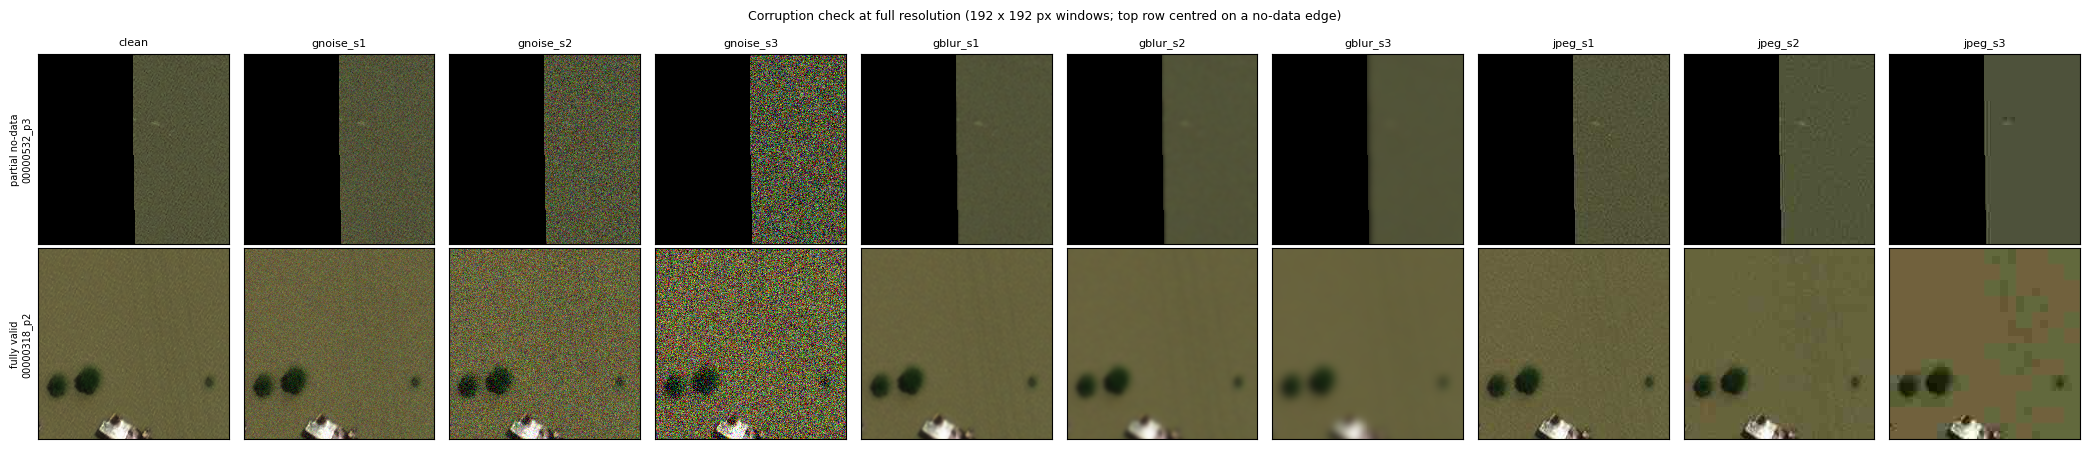

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.ndimage import binary_dilation
# 192 px window, centred on a no-data edge if the crop has one
def window(tid):
    pre, post, mask, valid = load_crop(X, ROWMAP[tid])
    nod = post.sum(2) == 0
    if nod.any() and (~nod).any():
        edge = np.argwhere(binary_dilation(nod, iterations=4) & ~nod)
        y, x = edge[len(edge) // 2]
    else:
        y, x = 256, 256
    y0, x0 = int(np.clip(y - 96, 0, 512 - 192)), int(np.clip(x - 96, 0, 512 - 192))
    return post, (slice(y0, y0 + 192), slice(x0, x0 + 192))
# One crop with the most balanced partial no-data, and one fully valid crop
check = [max(part, key=lambda t: min(CROPS.loc[t, "valid_px"], 512 * 512 - CROPS.loc[t, "valid_px"])) if part else full[0], full[len(full) // 2]]
# Every condition at full resolution
f, ax = plt.subplots(2, len(CONDITIONS), figsize=(2.1 * len(CONDITIONS), 4.6))
for i, tid in enumerate(check):
    post, w = window(tid)
    for j, c in enumerate(CONDITIONS):
        ax[i, j].imshow(corruption.corrupt(post, c, tid)[w], interpolation="nearest"); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        if i == 0: ax[i, j].set_title(c, fontsize=8)
    ax[i, 0].set_ylabel(("partial no-data\n" if i == 0 else "fully valid\n") + tid.replace("nepal-flooding_", ""), fontsize=7)
f.suptitle("Corruption check at full resolution (192 x 192 px windows; top row centred on a no-data edge)", fontsize=9)
f.tight_layout(); f.savefig(out("figures", "phase6", "corruption_artifact_check.png"), dpi=200, bbox_inches="tight"); plt.show()

## 8. Prediction maps, clean and severity 3, six sample crops
Seed 0 of each main family: each map comes from a single checkpoint, not a family average. Inputs are rebuilt with the corruption notebook's code and their SHA-256 checked against the stored input hashes.
Colours: damage severity on one ordinal blue ramp (no damage light to destroyed dark), background light grey, no-data
mid grey.

In [ ]:
from corruption_eval import CorruptedTiles
from floodsitrep.cv.models import load_checkpoint
DEV = torch.device("cuda")
# Conditions shown
SHOW_CONDS = ["clean", "gnoise_s3", "gblur_s3", "jpeg_s3"]
# Same six samples as the corruption notebook (same rule; checked against the saved sample files)
elig = CROPS[(CROPS.building_px >= 0.05 * 512 * 512) & (CROPS.valid_px >= 0.99 * 512 * 512)].reset_index()
SAMPLES = list(elig.crop_id.iloc[np.linspace(0, len(elig) - 1, 6).round().astype(int)])
saved = sorted({f.split("__")[0] for f in os.listdir(out("corruption", "samples"))})
assert sorted(SAMPLES) == saved, "sample rule gives different crops than Stage 5"
# Seed-0 model of each main family, plus the ablation
MAIN = {f: RUNS[f][0] for f in ("M0", "M1 CE", "M1 DF", "M2", "M3")}
ABL = "exploratory_abl_m1fusion_dualhead_ce_s0"
paths = dict(zip(CKP.run, CKP.path))
MODELS = {r: load_checkpoint(paths[r], "cuda")[0].eval() for r in list(MAIN.values()) + [ABL]}
# Rebuild each input, check its hash against the corruption notebook's, and predict
PRED, INP = {}, {}
with torch.no_grad():
    for c in SHOW_CONDS:
        ds = CorruptedTiles(X, MAN, c)
        H = pd.read_csv(out("corruption", "input_hashes", f"{c}.csv")).set_index("crop_id")
        for tid in SAMPLES:
            it = ds[ORDER.index(tid)]
            assert it["post_sha256"] == H.loc[tid, "post_sha256"], f"{tid} {c}: input differs from Stage 5"
            INP[(tid, c)] = it
            for r, m in MODELS.items():
                with torch.autocast("cuda"):
                    PRED[(tid, c, r)] = m(it["pre"][None].to(DEV), it["post"][None].to(DEV)).argmax(1)[0].cpu().numpy().astype(np.uint8)
# Save all predictions
np.savez_compressed(out("results", "phase6", "qualitative_predictions_seed0.npz"),
                    **{f"{t}|{c}|{r}": v for (t, c, r), v in PRED.items()})
print("predictions:", len(PRED), "| all inputs match the Stage 5 hashes")
# Colour map: background, the four damage classes on a blue ramp, no-data grey
CM = ListedColormap(["#f0efec", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b", "#9a9a95"])   # 0-4 classes, 5 = no-data
def show_mask(a, m, valid):
    a.imshow(np.where(valid, m, 5), cmap=CM, vmin=0, vmax=5, interpolation="nearest")
from matplotlib.patches import Patch
LEG = [Patch(color=c, label=l) for c, l in zip(["#f0efec", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b", "#9a9a95"],
                                                ["background", "no damage", "minor", "major", "destroyed", "no-data"])]
# Undo the ImageNet normalisation for display
def denorm(t):
    m, s = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    return np.clip((t.numpy().transpose(1, 2, 0) * s + m), 0, 1)
# One figure per sample for the main families, and one for the ablation
for tid in SAMPLES:
    for kind, runs in (("main", MAIN), ("EXPLORATORY", {"EXPLORATORY ablation (1 seed)": ABL, "ref: M1 CE s0": MAIN["M1 CE"], "ref: M3 s0": MAIN["M3"]})):
        cols = ["pre", "post (as given)", "ground truth"] + list(runs)
        f, ax = plt.subplots(len(SHOW_CONDS), len(cols), figsize=(2.0 * len(cols), 2.1 * len(SHOW_CONDS)))
        for i, c in enumerate(SHOW_CONDS):
            it = INP[(tid, c)]; valid = it["valid"].numpy()
            ax[i, 0].imshow(denorm(it["pre"])); ax[i, 1].imshow(denorm(it["post"]))
            show_mask(ax[i, 2], it["mask"].numpy().clip(0, 4), valid)
            for j, (lab, r) in enumerate(runs.items()):
                show_mask(ax[i, 3 + j], PRED[(tid, c, r)], valid)
            ax[i, 0].set_ylabel(c, fontsize=9)
        for j, lab in enumerate(cols):
            ax[0, j].set_title(lab + (" (s0, post-hoc)" if lab == "M3" else " (s0)" if lab in MAIN else ""), fontsize=8)
        for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
        f.legend(handles=LEG, loc="lower center", ncol=6, fontsize=8, frameon=False)
        title = ("EXPLORATORY two-head ablation (ONE seed) with seed-0 references; not part of the primary comparison"
                 if kind == "EXPLORATORY" else "Seed-0 predictions of the five main families; M3 is a post-hoc evaluation")
        f.suptitle(f"{tid}: {title}", fontsize=9); f.tight_layout(rect=(0, 0.04, 1, 1))
        sub = "qualitative" if kind == "main" else "qualitative_EXPLORATORY_ablation"
        f.savefig(out("figures", "phase6", sub, f"{tid}{'_EXPLORATORY' if kind != 'main' else ''}.png"), dpi=160, bbox_inches="tight")
        plt.close(f)
# per-sample pixel agreement with ground truth (valid pixels), for a small table next to the maps
QT = []
for tid in SAMPLES:
    for c in SHOW_CONDS:
        it = INP[(tid, c)]; v = it["valid"].numpy(); g = it["mask"].numpy()
        for lab, r in list(MAIN.items()) + [("EXPLORATORY ablation", ABL)]:
            p = PRED[(tid, c, r)]; b = (g >= 1) & (g <= 4) & v
            QT.append({"crop": tid, "condition": c, "model": lab, "pixel_accuracy": float((p == g)[v].mean()),
                       "building_px_found": float((p[b] > 0).mean()) if b.any() else np.nan,
                       "building_px_damage_correct": float((p[b] == g[b]).mean()) if b.any() else np.nan})
QT_DF = pd.DataFrame(QT); QT_DF.to_csv(out("results", "phase6", "qualitative_sample_agreement.csv"), index=False)
print(QT_DF.groupby(["condition", "model"])[["building_px_found", "building_px_damage_correct"]].mean().round(3).unstack(0).to_string())

predictions: 144 | all inputs match the Stage 5 hashes
                     building_px_found                            building_px_damage_correct                           
condition                        clean gblur_s3 gnoise_s3 jpeg_s3                      clean gblur_s3 gnoise_s3 jpeg_s3
model                                                                                                                  
EXPLORATORY ablation             0.802    0.348     0.566   0.801                      0.578    0.320     0.000   0.704
M0                               0.603    0.610     0.240   0.582                      0.493    0.524     0.000   0.457
M1 CE                            0.808    0.340     0.640   0.728                      0.563    0.302     0.000   0.548
M1 DF                            0.611    0.198     0.037   0.564                      0.567    0.194     0.019   0.525
M2                               0.897    0.875     0.777   0.874                      0.303    0.806    

## 9. Preservation check and summary

In [ ]:
# Nothing outside m3_experiments/ may have changed
AFTER = snapshot()
ch = {"added": sorted(set(AFTER) - set(BEFORE)), "removed": sorted(set(BEFORE) - set(AFTER)),
      "changed": sorted(k for k in set(BEFORE) & set(AFTER) if BEFORE[k] != AFTER[k])}
SESSION["session_end"] = datetime.datetime.now().isoformat(timespec="seconds")
# Summary of everything above, saved and printed
KEEP = ["A", "condition", "metric", "comparison", "difference_A_minus_B", "ci95_images_lo", "ci95_images_hi",
        "ci95_images_and_seeds_lo", "ci95_images_and_seeds_hi", "seed_pairs_min", "seed_pairs_max", "seed_pairs_same_sign_as_mean"]
SUMMARY = {"session": SESSION, "precheck_repeated_hashes": PRE1, "timing_reconciliation": RECON,
           "timing_gpu_per_family": PF.round(2).to_dict(orient="records"),
           "between_family": BF_DF[BF_DF.metric.isin(["xview2_pixel_score", "damage_macro_f1", "building_iou"])][KEEP].round(4).to_dict(orient="records"),
           "ground_truth_support_px": SUPPORT, "ground_truth_buildings_no_minor_major_destroyed": [int(x) for x in bld],
           "investigation_cases": INV_DF.round(4).to_dict(orient="records"),
           "investigation_per_seed": PS_DF.round(4).to_dict(orient="records"),
           "artifact_summary": ART_SUM.round(3).reset_index().to_dict(orient="records"),
           "qualitative_samples": SAMPLES,
           "qualitative_agreement_mean": QT_DF.groupby(["model", "condition"])[["building_px_found", "building_px_damage_correct"]].mean().round(3).reset_index().to_dict(orient="records"),
           "preservation": "NOTHING OUTSIDE m3_experiments CHANGED" if not any(ch.values()) else f"DIFFERENCES: {ch}"}
jdump(SUMMARY, out("results", "phase6", f"phase6_summary_{datetime.datetime.now():%Y%m%d_%H%M}.json"))
print(json.dumps(SUMMARY, indent=1, default=str))

{
 "session": {
  "session_start": "2026-11-21T05:46:59",
  "gpu": "NVIDIA L4",
  "session_end": "2026-11-21T06:00:07"
 },
 "precheck_repeated_hashes": {
  "crops_with_valid_px_0": 66,
  "of_which_in_repeated_groups_clean": 66,
  "repeated_crops_all_valid_px_0": true,
  "same_repeated_set_in_every_condition": true,
  "valid_pixels_in_repeated_crops": 0,
  "note": "repeated hashes are crops whose post image is entirely black (no data); they contribute no valid pixels to any metric"
 },
 "timing_reconciliation": {
  "full_passes": 10,
  "sum_wall_h": 0.9589760377166663,
  "sum_gpu_h": 0.8397324026186163,
  "sum_gpu_per_checkpoint_h": 0.839736111111111,
  "gpu_totals_agree": true,
  "sum_scoring_worker_cpu_h": 0.9031322115397051,
  "scoring_workers": 4,
  "scoring_overlapped": "yes: CPU scoring runs in 4 processes while the GPU works; backpressure = 0 s",
  "session_h_stage5": 1.25,
  "session_minus_condition_passes_h": 0.2910239622833337,
  "session_overhead_includes": "setup, repo insta

## End of notebook
Releases the Colab runtime so it stops using compute units.

In [ ]:
# Release the Colab runtime
from google.colab import runtime
runtime.unassign()